# 04 - Model Comparison: SVM, Naive Bayes, Random Forest (+ baselines)
**Lab link:** Exp 9 (Naive Bayes), Exp 10 (SVM), Unit V theory (ensembles -> Random Forest)

| Model | Features | Notes |
|-------|----------|-------|
| Calibrated Linear SVM (`C=0.5`) | full TF-IDF | margin classifier; calibration gives probabilities |
| Multinomial Naive Bayes (`alpha=0.1`) | full TF-IDF | assumes features are independent; good for counts |
| Random Forest | 100-dim SVD | ensemble of trees |

> *Scaling for SVM:* TF-IDF rows are already length-normalised (every row has L2 norm 1), so no extra scaling is needed.

We combine these with the results from notebook 03 into one comparison table.

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
RAW = Path("../data/raw")
PROC = Path("../data/processed")     # cleaned text + feature matrices made in notebook 02
MODELS = Path("../models")
ASSETS = Path("../assets")
for folder in (PROC, MODELS, ASSETS):
    folder.mkdir(exist_ok=True)

from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score


def evaluate(y_true, probs):
    """Returns (column-averaged ROC-AUC, macro F1 at 0.5, list of per-label AUCs)."""
    y_true = np.asarray(y_true)
    aucs = []
    for i in range(6):
        if y_true[:, i].sum() == 0:          # label missing in this split -> cannot compute AUC
            aucs.append(np.nan)
        else:
            aucs.append(roc_auc_score(y_true[:, i], probs[:, i]))
    f1 = f1_score(y_true, (probs >= 0.5).astype(int), average="macro", zero_division=0)
    return np.nanmean(aucs), f1, aucs


def to_matrix(proba_list):
    """Tree / KNN models give a list of (n,2) arrays (one per label) -> one (n,6) matrix."""
    return np.column_stack([p[:, 1] if p.shape[1] == 2 else np.zeros(len(p)) for p in proba_list])

import scipy.sparse as sp

X_train = sp.load_npz(PROC / "X_train_tfidf.npz")
X_val = sp.load_npz(PROC / "X_val_tfidf.npz")
y_train = pd.read_csv(PROC / "y_train.csv")[LABELS].values
y_val = pd.read_csv(PROC / "y_val.csv")[LABELS].values
print("TF-IDF train:", X_train.shape, "| validation:", X_val.shape)

X_train_svd = np.load(PROC / "X_train_svd.npy")
X_val_svd = np.load(PROC / "X_val_svd.npy")
results = []
per_label_auc = {}

TF-IDF train: (127656, 30000) | validation: (31915, 30000)


## 1. Calibrated Linear SVM

In [2]:
svm = OneVsRestClassifier(CalibratedClassifierCV(LinearSVC(C=0.5), cv=3))
start = time.time()
svm.fit(X_train, y_train)
svm_time = time.time() - start

svm_probs = svm.predict_proba(X_val)
auc, f1, per_label = evaluate(y_val, svm_probs)
results.append({"Model": "Calibrated Linear SVM", "Features": "TF-IDF (30k)",
                "ROC-AUC": auc, "Macro F1": f1, "Train time (s)": svm_time})
per_label_auc["Calibrated Linear SVM"] = per_label
print(f"SVM -> ROC-AUC {auc:.4f} | Macro F1 {f1:.4f} | {svm_time:.0f} s")

SVM -> ROC-AUC 0.9812 | Macro F1 0.5770 | 151 s


## 2. Multinomial Naive Bayes

In [3]:
nb = OneVsRestClassifier(MultinomialNB(alpha=0.1))
start = time.time()
nb.fit(X_train, y_train)
nb_time = time.time() - start

nb_probs = nb.predict_proba(X_val)
auc, f1, per_label = evaluate(y_val, nb_probs)
results.append({"Model": "Multinomial Naive Bayes", "Features": "TF-IDF (30k)",
                "ROC-AUC": auc, "Macro F1": f1, "Train time (s)": nb_time})
per_label_auc["Multinomial Naive Bayes"] = per_label
print(f"Naive Bayes -> ROC-AUC {auc:.4f} | Macro F1 {f1:.4f} | {nb_time:.1f} s")

Naive Bayes -> ROC-AUC 0.9662 | Macro F1 0.4580 | 5.1 s


Naive Bayes is appropriate here because TF-IDF values are non-negative, behaving like weighted word counts (a requirement for Multinomial NB). It is *not* run just as a checkbox: we expect it to be fast but weaker, because its independence assumption is unrealistic for language.

## 3. Random Forest (ensemble)
A Random Forest averages many decision trees, which reduces the overfitting of a single tree. To keep training time reasonable we use 40 trees, and each tree sees only 30% of the data (`max_samples=0.3`). `RandomForestClassifier` handles the 6 labels together (multi-output).

In [4]:
rf = RandomForestClassifier(n_estimators=40, max_depth=14, min_samples_leaf=10,
                            max_samples=0.3, random_state=42, n_jobs=-1)
start = time.time()
rf.fit(X_train_svd, y_train)
rf_time = time.time() - start

rf_probs = to_matrix(rf.predict_proba(X_val_svd))
auc, f1, per_label = evaluate(y_val, rf_probs)
results.append({"Model": "Random Forest (40 trees)", "Features": "SVD (100)",
                "ROC-AUC": auc, "Macro F1": f1, "Train time (s)": rf_time})
per_label_auc["Random Forest (40 trees)"] = per_label
print(f"Random Forest -> ROC-AUC {auc:.4f} | Macro F1 {f1:.4f} | {rf_time:.0f} s")

Random Forest -> ROC-AUC 0.9310 | Macro F1 0.2798 | 12 s


## 4. Full comparison table (single split, seed 42)

In [5]:
old = pd.read_csv(PROC / "results_03.csv")
comparison = pd.concat([old, pd.DataFrame(results)], ignore_index=True)
comparison = comparison.sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
comparison.to_csv(PROC / "results_04.csv", index=False)
comparison.round(4)

,Model,Features,ROC-AUC,Macro F1,Train time (s)
0,Logistic Regression,TF-IDF (30k),0.9846,0.5557,74.1290
1,Calibrated Linear SVM,TF-IDF (30k),0.9812,0.5770,151.3047
2,Multinomial Naive Bayes,TF-IDF (30k),0.9662,0.4580,5.1340
3,Random Forest (40 trees),SVD (100),0.9310,0.2798,11.7241
4,"KNN (k=31, 40k subset)",SVD (100),0.8812,0.3092,0.0653
5,Decision Tree (depth=4),SVD (100),0.8715,0.2224,26.7317


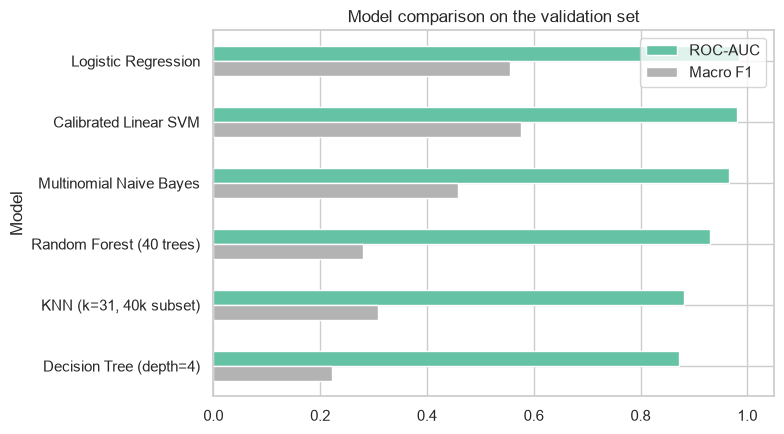

Top 2 models by ROC-AUC (these get tuned in notebook 05):
['Logistic Regression', 'Calibrated Linear SVM']


In [6]:
ax = comparison.set_index("Model")[["ROC-AUC", "Macro F1"]].plot(
    kind="barh", figsize=(8, 4.5), colormap="Set2")
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_title("Model comparison on the validation set")
plt.tight_layout()
plt.savefig(ASSETS / "model_comparison_series.png", dpi=150)
plt.show()

print("Top 2 models by ROC-AUC (these get tuned in notebook 05):")
print(comparison["Model"].head(2).tolist())

In [7]:
# Per-label AUC of the models trained here (LR/KNN/DT per-label numbers were printed in notebook 03)
pd.DataFrame(per_label_auc, index=LABELS).round(4)

,Calibrated Linear SVM,Multinomial Naive Bayes,Random Forest (40 trees)
toxic,0.9776,0.9495,0.9067
severe_toxic,0.9773,0.9835,0.9784
obscene,0.9879,0.9622,0.9439
threat,0.9793,0.9709,0.9117
insult,0.9801,0.9614,0.9348
identity_hate,0.9851,0.9695,0.9105


## Reading the results
* The models on the **full TF-IDF** (Logistic Regression, SVM) are expected to lead, because they keep word- and character-level detail.
* **Random Forest** should beat a single Decision Tree (ensembles reduce overfitting). If it did not here, the reason would be that both only see 100 compressed SVD numbers.
* **Naive Bayes** is the fastest but usually the weakest of the text-based models.
* Macro F1 at a fixed 0.5 threshold is low for rare labels - which is exactly why the final system uses a **3-tier decision** (Publish / Review / Remove) instead of one hard cut-off.

Next: `05_tuning_and_benchmark.ipynb` tunes the top 2 models and repeats the evaluation with 3 different random splits.